<a href="https://colab.research.google.com/github/Geethima-Rajapaksha/image-classification-to-a-bussiness-application/blob/main/GroupAssignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Download Dataset-version'geethima-rajapaksha'
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="2psuTNT48Clp58CXXL10"
project = rf.workspace("geethima-rajapaksha").project("plantvillage-class-t8lzz-5q7zv")
version = project.version(1)
dataset = version.download("folder")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.8/302.8 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 59.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.2 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to PlantVillage-Class-1 in folder:: 100%|██████████| 5968/5968 [00:01<00:00, 4682.89it/s]


In [ ]:
#See inside the folder
import os

dataset_path = "PlantVillage-Class-1"

# List all class folders
for split in os.listdir(dataset_path):
    split_path = os.path.join(dataset_path, split)
    if os.path.isdir(split_path):
        print(f"\n📁 {split}/")
        for class_name in os.listdir(split_path):
            class_path = os.path.join(split_path, class_name)
            if os.path.isdir(class_path):
                count = len(os.listdir(class_path))
                print(f"   {class_name}: {count} images")



📁 test/
   Apple___Apple_Black_Rot: 62 images
   Potato___Potato_Healthy: 20 images
   Potato___Potato_Late_Blight: 63 images
   Corn___Corn_Healthy: 66 images
   Apple___Cedar_Apple_Rust: 27 images
   Corn___Corn_Cercospora_Leaf_Spot_Gray: 51 images
   Apple___Apple_Healthy: 65 images
   Apple___Apple_scab: 63 images
   Corn___Corn_Common_Rust: 60 images
   Corn___Corn_Northern_Leaf_Blight: 61 images
   Potato___Potato_Early_Blight: 61 images

📁 valid/
   Apple___Apple_Black_Rot: 62 images
   Potato___Potato_Healthy: 20 images
   Potato___Potato_Late_Blight: 64 images
   Corn___Corn_Healthy: 66 images
   Apple___Cedar_Apple_Rust: 28 images
   Corn___Corn_Cercospora_Leaf_Spot_Gray: 52 images
   Apple___Apple_Healthy: 65 images
   Apple___Apple_scab: 63 images
   Corn___Corn_Common_Rust: 61 images
   Corn___Corn_Northern_Leaf_Blight: 62 images
   Potato___Potato_Early_Blight: 61 images

📁 train/
   Apple___Apple_Black_Rot: 497 images
   Potato___Potato_Healthy: 112 images
   Potato___P

In [ ]:
#Folder structure
PlantVillage-Class-1/
├── train/
│   ├── Potato___Potato_Healthy/
│   ├── Potato___Potato_Late_Blight/
│   └── corn___common_Rust/
├── valid/
└── test/

SyntaxError: invalid character '├' (U+251C) (1293555528.py, line 3)

In [ ]:
#Filter to 3 classes
import shutil
import os

source_root = "PlantVillage-Class-1"
target_root = "MyDataset"

my_classes = [
    "Potato___Potato_Healthy",
    "Potato___Potato_Late_Blight",
    "corn___common_Rust"
]

for split in ["train", "valid", "test"]:
    for class_name in my_classes:
        src = os.path.join(source_root, split, class_name)
        dst = os.path.join(target_root, split, class_name)
        if os.path.exists(src):
            shutil.copytree(src, dst, dirs_exist_ok=True)
            print(f"Copied {split}/{class_name}: {len(os.listdir(src))} images")
        else:
            print(f"⚠️ Not found: {src}")

Copied train/Potato___Potato_Healthy: 112 images
Copied train/Potato___Potato_Late_Blight: 507 images
⚠️ Not found: PlantVillage-Class-1/train/corn___common_Rust
Copied valid/Potato___Potato_Healthy: 20 images
Copied valid/Potato___Potato_Late_Blight: 64 images
⚠️ Not found: PlantVillage-Class-1/valid/corn___common_Rust
Copied test/Potato___Potato_Healthy: 20 images
Copied test/Potato___Potato_Late_Blight: 63 images
⚠️ Not found: PlantVillage-Class-1/test/corn___common_Rust


In [ ]:
#fix
my_classes = [
    "Potato___Potato_Healthy",
    "Potato___Potato_Late_Blight",
    "Corn___Corn_Common_Rust"
]

for split in ["train", "valid", "test"]:
    class_name = "Corn___Corn_Common_Rust"
    src = os.path.join(source_root, split, class_name)
    dst = os.path.join(target_root, split, class_name)
    if os.path.exists(src):
        shutil.copytree(src, dst, dirs_exist_ok=True)
        print(f"Copied {split}/{class_name}: {len(os.listdir(src))} images")
    else:
        print(f"⚠️ Still not found: {src}")

Copied train/Corn___Corn_Common_Rust: 482 images
Copied valid/Corn___Corn_Common_Rust: 61 images
Copied test/Corn___Corn_Common_Rust: 60 images


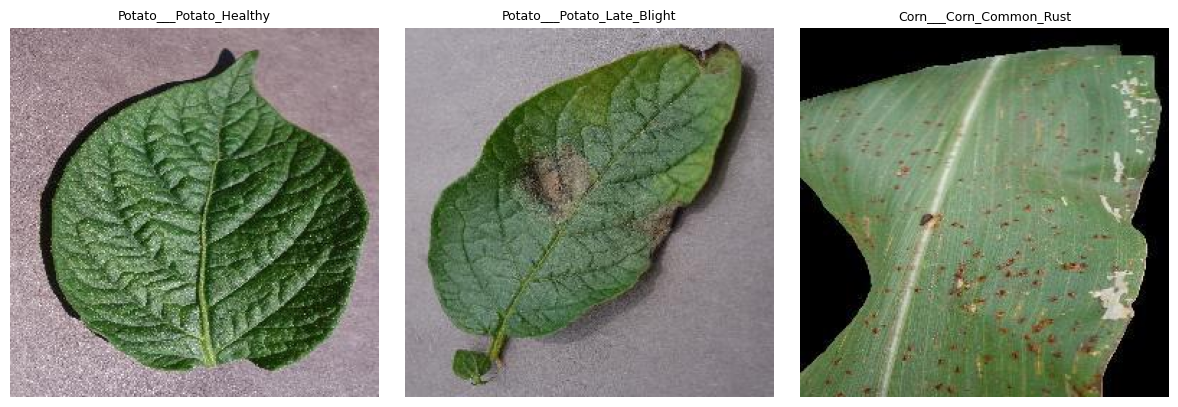

In [ ]:
#Display a few sample images
import matplotlib.pyplot as plt
from PIL import Image
import os

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i, class_name in enumerate(my_classes):
    class_folder = os.path.join("MyDataset", "train", class_name)
    sample_image = os.listdir(class_folder)[0]
    img = Image.open(os.path.join(class_folder, sample_image))
    axes[i].imshow(img)
    axes[i].set_title(class_name, fontsize=9)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

{'Potato___Potato_Healthy': 112, 'Potato___Potato_Late_Blight': 507, 'Corn___Corn_Common_Rust': 482}


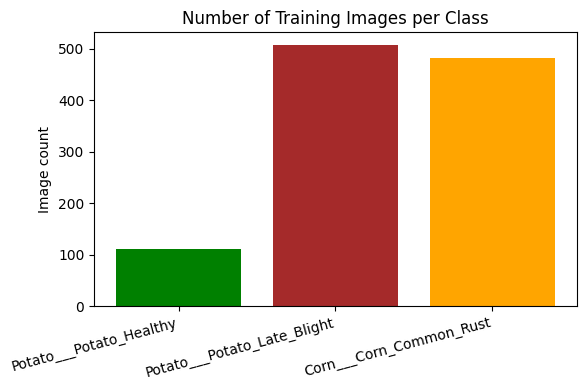

In [ ]:
#Check class balance numerically
import matplotlib.pyplot as plt

counts = {}
for class_name in my_classes:
    class_folder = os.path.join("MyDataset", "train", class_name)
    counts[class_name] = len(os.listdir(class_folder))

print(counts)

plt.figure(figsize=(6,4))
plt.bar(counts.keys(), counts.values(), color=["green", "brown", "orange"])
plt.title("Number of Training Images per Class")
plt.ylabel("Image count")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
#Check images size
for class_name in my_classes:
    class_folder = os.path.join("MyDataset", "train", class_name)
    sample_files = os.listdir(class_folder)[:3]
    print(f"\n{class_name}:")
    for f in sample_files:
        img = Image.open(os.path.join(class_folder, f))
        print(f"  {f}: {img.size}")


Potato___Potato_Healthy:
  00fc2ee5-729f-4757-8aeb-65c3355874f2___RS_HL-1864_JPG.rf.9c2eb5420106285964c194801163d662.jpg: (256, 256)
  a1abff90-34e5-464d-b4d3-0c09f5924900___RS_HL-5414_JPG.rf.bd83ed5d5037bc19cb867d1d20bd4fa0.jpg: (256, 256)
  61b05f0a-14bc-4c8f-a256-57c8b8898d8c___RS_HL-1769_JPG.rf.f47be1162c03d4a2d998c8c0c402b996.jpg: (256, 256)

Potato___Potato_Late_Blight:
  006cc01a-1888-4326-9b62-a65cb55a6377___RS_LB-5207_JPG.rf.b4ca8a5370b46f656f5d08fa632ba29e.jpg: (256, 256)
  6d51bd53-2556-410c-b151-547c83a06287___RS_LB-3276_JPG.rf.adaa3d38a3f3e5aef3fcc7409ca497e6.jpg: (256, 256)
  44112cb9-7423-4983-bb9a-cb32e3ea9ac3___RS_LB-2793_JPG.rf.970e58354ab8ae09ccfc8d83b65d43b5.jpg: (256, 256)

Corn___Corn_Common_Rust:
  Corn_Common_Rust-489-_JPG.rf.bff42cb5c8e3c132001645f9134c0c8d.jpg: (256, 256)
  Corn_Common_Rust-649-_JPG.rf.d1c474e1bbbd11105a8760d9722e88be.jpg: (256, 256)
  Corn_Common_Rust-608-_JPG.rf.b4f43ffa558cc63a6d325578497c40b4.jpg: (256, 256)


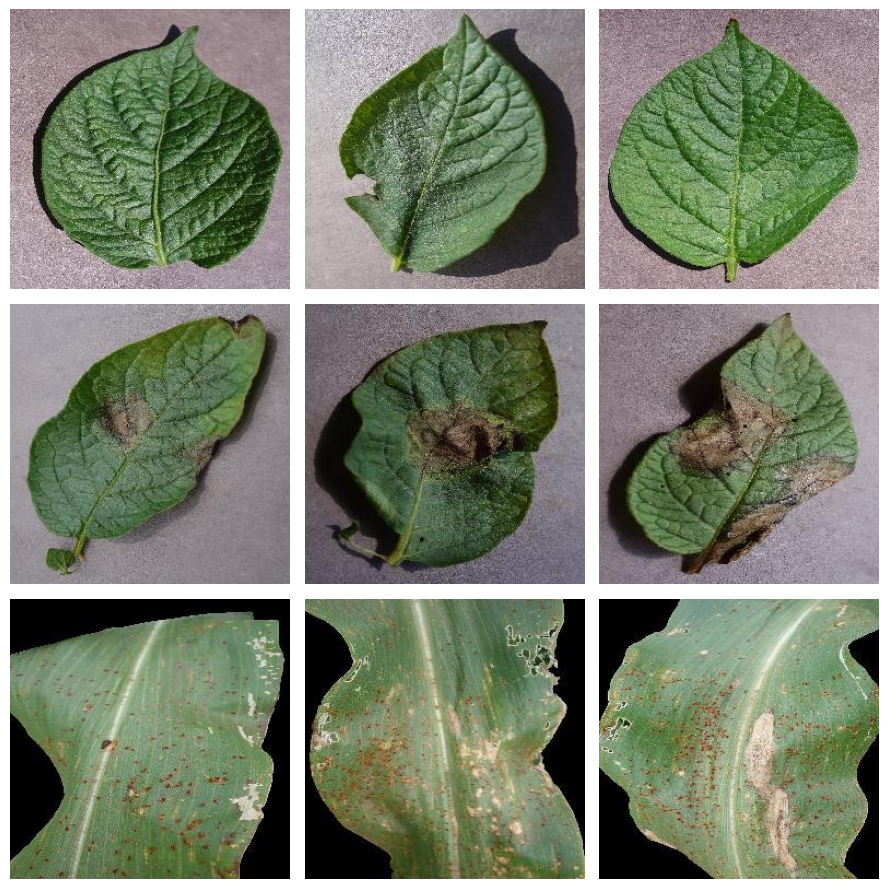

In [ ]:
#See more images
fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for i, class_name in enumerate(my_classes):
    class_folder = os.path.join("MyDataset", "train", class_name)
    sample_files = os.listdir(class_folder)[:3]
    for j, f in enumerate(sample_files):
        img = Image.open(os.path.join(class_folder, f))
        axes[i, j].imshow(img)
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_ylabel(class_name, fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
#Load the data properly
import tensorflow as tf

IMG_SIZE = (224, 224)  # MobileNetV2's expected input size
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    "MyDataset/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "MyDataset/valid",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

class_names = train_ds.class_names
print(class_names)


Found 1101 files belonging to 3 classes.
Found 145 files belonging to 3 classes.
['Corn___Corn_Common_Rust', 'Potato___Potato_Healthy', 'Potato___Potato_Late_Blight']


In [ ]:
#Normalize pixel values
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

In [ ]:
#Build the Model(Transfer Learning)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False  # freeze pretrained layers

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax")  # 3 classes
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
#Train the Model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 73s 2s/step - accuracy: 0.9382 - loss: 0.1425 - val_accuracy: 0.9862 - val_loss: 0.0446
Epoch 2/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 74s 2s/step - accuracy: 0.9882 - loss: 0.0261 - val_accuracy: 0.9655 - val_loss: 0.0522
Epoch 3/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - accuracy: 0.9955 - loss: 0.0141 - val_accuracy: 0.9655 - val_loss: 0.0634
Epoch 4/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.9973 - loss: 0.0123 - val_accuracy: 0.9724 - val_loss: 0.0715
Epoch 5/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accuracy: 0.9991 - loss: 0.0069 - val_accuracy: 0.9724 - val_loss: 0.0479
Epoch 6/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 98s 2s/step - accuracy: 1.0000 - loss: 0.0042 - val_accuracy: 0.9655 - val_loss: 0.0480
Epoch 7/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 62s 2s/step - accuracy: 1.0000 - loss: 0.0027 - val_accuracy: 0.9724 - val_loss: 0.0508
Epoch 8/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 0.9655 - val_loss:

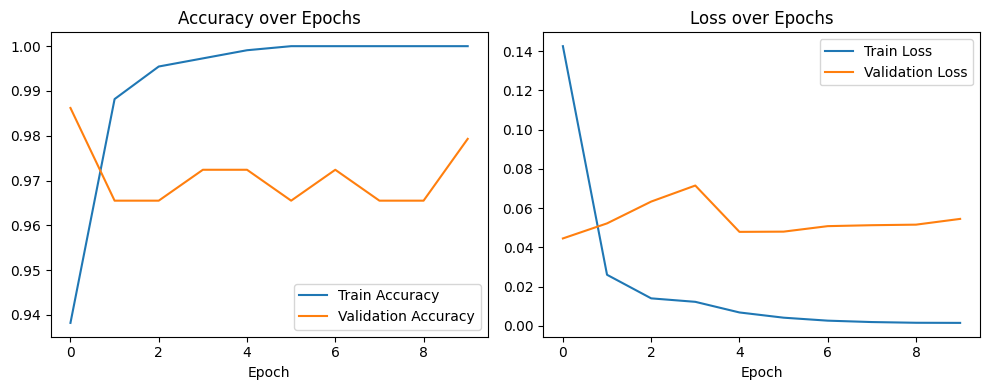

In [ ]:
#Plot training curves
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy over Epochs")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss over Epochs")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()


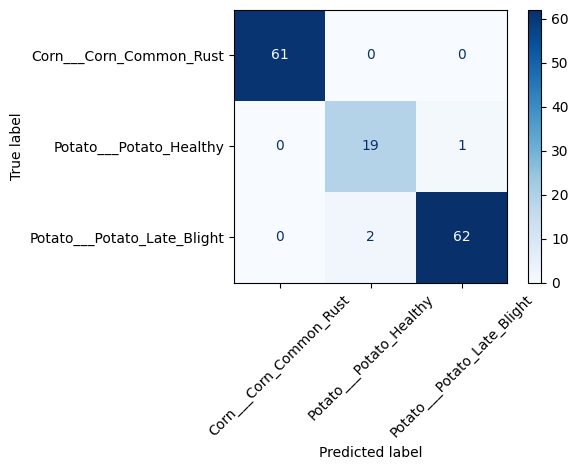

In [ ]:
#Confusion Matrix + Example Prediction
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Get true labels and predictions from validation set
y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.tight_layout()
plt.show()

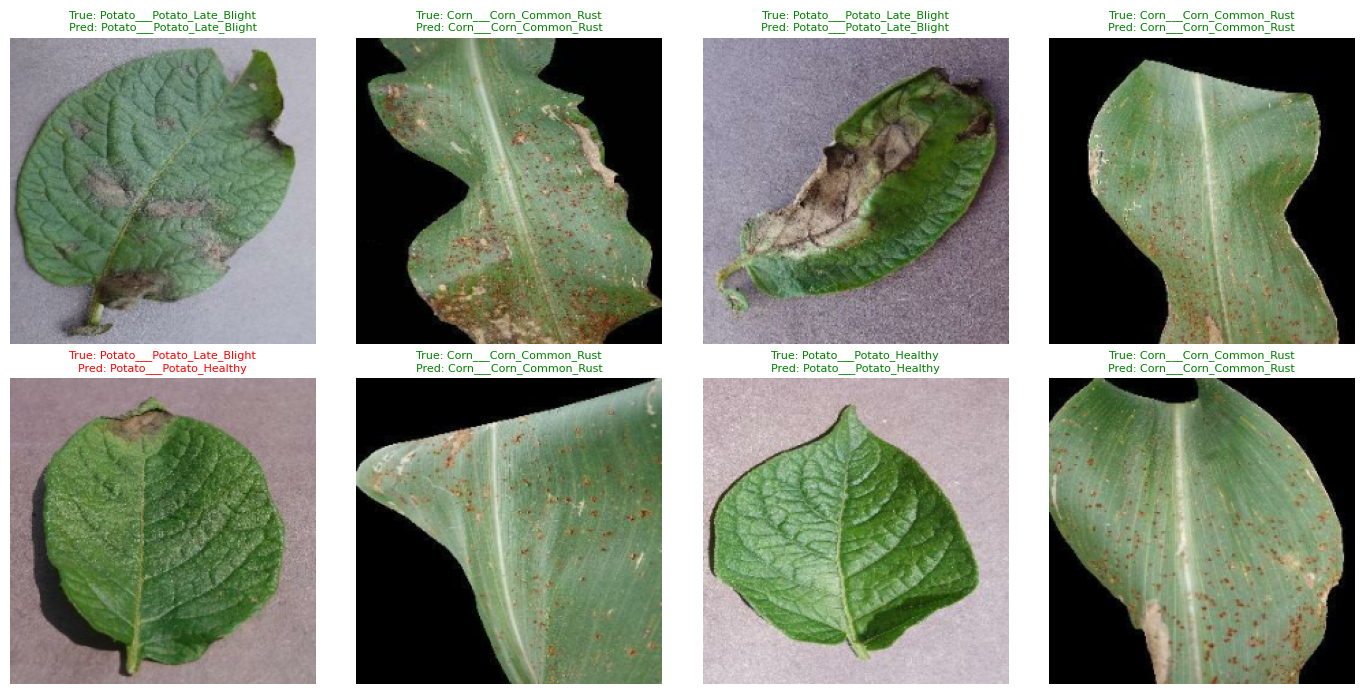

In [ ]:
#Show actual correct/incorrect prediction examples
import matplotlib.pyplot as plt
import numpy as np

# Get one batch from validation set
for images, labels in val_ds.take(1):
    preds = model.predict(images, verbose=0)
    true_idx = np.argmax(labels.numpy(), axis=1)
    pred_idx = np.argmax(preds, axis=1)

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()

    for i in range(8):
        axes[i].imshow(images[i].numpy())
        true_label = class_names[true_idx[i]]
        pred_label = class_names[pred_idx[i]]
        color = "green" if true_idx[i] == pred_idx[i] else "red"
        axes[i].set_title(f"True: {true_label}\nPred: {pred_label}", fontsize=8, color=color)
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


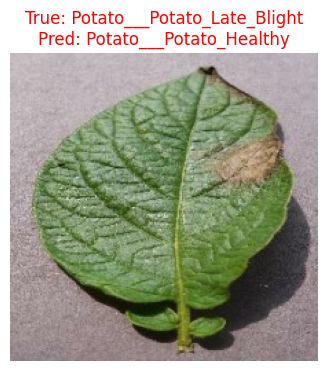

In [ ]:
# Search across the whole validation set for a wrong prediction
found_wrong = False

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    true_idx = np.argmax(labels.numpy(), axis=1)
    pred_idx = np.argmax(preds, axis=1)

    wrong_indices = np.where(true_idx != pred_idx)[0]

    if len(wrong_indices) > 0:
        idx = wrong_indices[0]
        plt.figure(figsize=(4,4))
        plt.imshow(images[idx].numpy())
        plt.title(f"True: {class_names[true_idx[idx]]}\nPred: {class_names[pred_idx[idx]]}", color="red")
        plt.axis("off")
        plt.show()
        found_wrong = True
        break

if not found_wrong:
    print("No misclassifications found in this pass — try re-running, batching order may differ.")


In [ ]:
#fix upload file
import zipfile
import os

with zipfile.ZipFile("potato leaves.zip", "r") as zip_ref:
    zip_ref.extractall("potato_test_images")

print(os.listdir("potato_test_images"))


['potato leaves']


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step


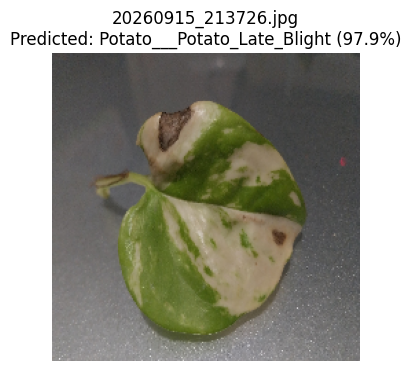

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step


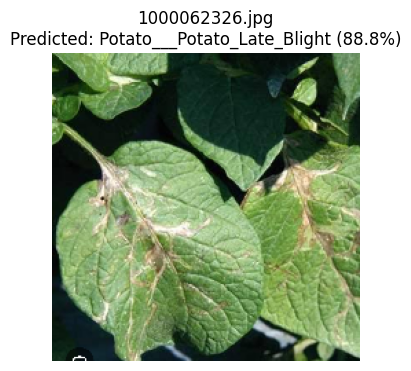

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step


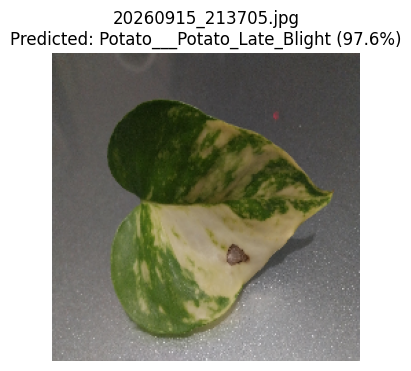

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step


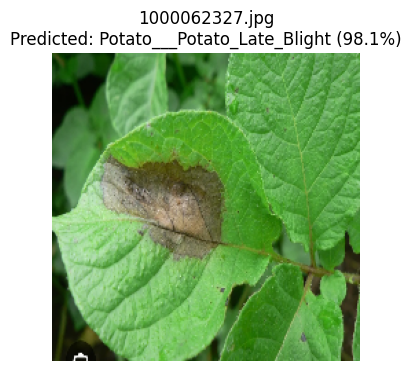

In [ ]:
#predict images
from tensorflow.keras.preprocessing import image
import numpy as np
import os

test_folder = "potato_test_images"

for root, dirs, files in os.walk(test_folder):
    for fname in files:
        if fname.lower().endswith((".jpg", ".jpeg", ".png")):
            fpath = os.path.join(root, fname)
            img = image.load_img(fpath, target_size=(224, 224))
            img_array = image.img_to_array(img) / 255.0
            img_array = np.expand_dims(img_array, axis=0)

            pred = model.predict(img_array)
            predicted_class = class_names[np.argmax(pred)]
            confidence = np.max(pred) * 100

            plt.figure(figsize=(4,4))
            plt.imshow(img)
            plt.title(f"{fname}\nPredicted: {predicted_class} ({confidence:.1f}%)")
            plt.axis("off")
            plt.show()
